# Titanic: Survival Prediction (Kaggle)

My first Kaggle competition: predicting which passengers survived the Titanic, with feature engineering, sklearn pipelines and error analysis.

## Problem

Predict whether a passenger survived (binary classification) from their ticket class, sex, age, family and ticket data. The metric is accuracy on Kaggle's hidden test set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import cross_val_score, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay

## Data

Kaggle "Titanic - Machine Learning from Disaster": `train.csv` has 891 passengers with the `Survived` label, `test.csv` has 418 passengers without it.

In [2]:
df = pd.read_csv('data/train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## EDA

### Main survival factors

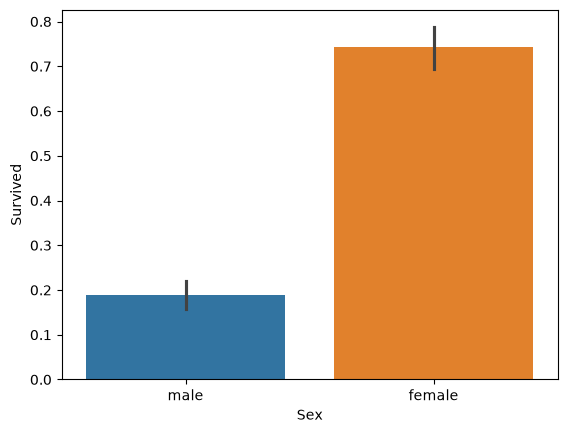

In [6]:
sns.barplot(data=df, x='Sex', y='Survived', hue='Sex');

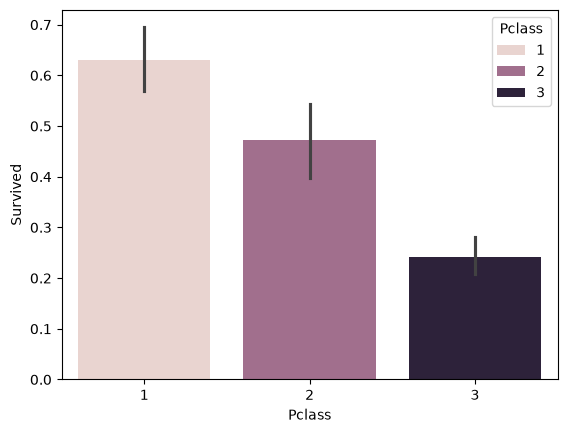

In [7]:
sns.barplot(data=df, x='Pclass', y='Survived', hue='Pclass');

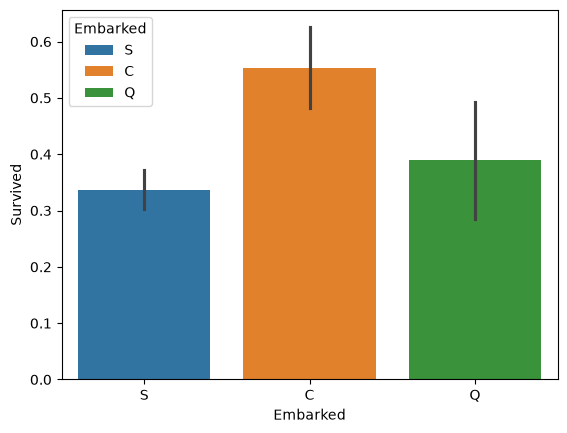

In [8]:
sns.barplot(data=df, x='Embarked', y='Survived', hue='Embarked');

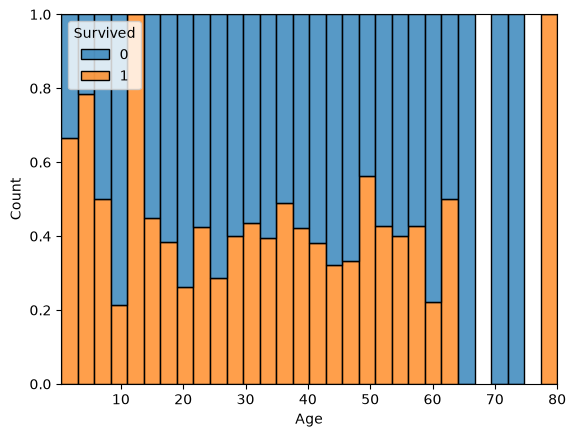

In [9]:
sns.histplot(data=df, x='Age', hue='Survived', multiple='fill', bins=30);

Women, first-class passengers, passengers from Cherbourg and children survived more often.

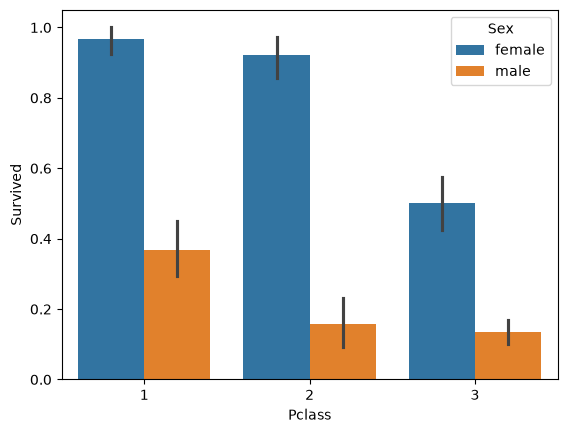

In [10]:
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex')
plt.savefig('images/survival_by_class_sex.png', bbox_inches='tight');

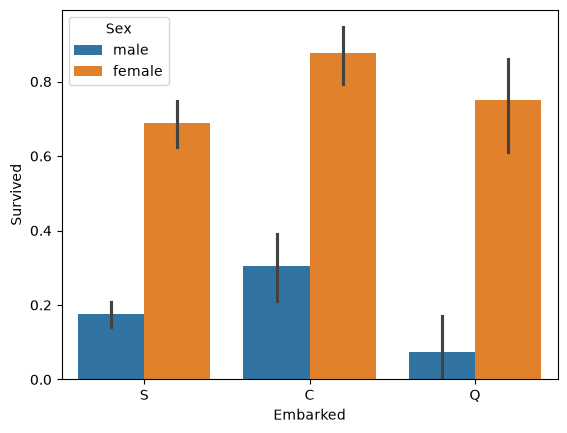

In [11]:
sns.barplot(data=df, x='Embarked', y='Survived', hue='Sex');

### Is the port of embarkation just a proxy for class?

In [12]:
pd.crosstab(df['Embarked'], df['Pclass'], normalize='index')

Pclass,1,2,3
Embarked,,,
C,0.505952,0.101190,0.392857
Q,0.025974,0.038961,0.935065
S,0.197205,0.254658,0.548137


In [13]:
df.groupby(['Pclass', 'Embarked'])['Survived'].agg(['mean', 'count'])

mean  count
Pclass Embarked                 
1      C         0.694118     85
       Q         0.500000      2
       S         0.582677    127
2      C         0.529412     17
       Q         0.666667      3
       S         0.463415    164
3      C         0.378788     66
       Q         0.375000     72
       S         0.189802    353

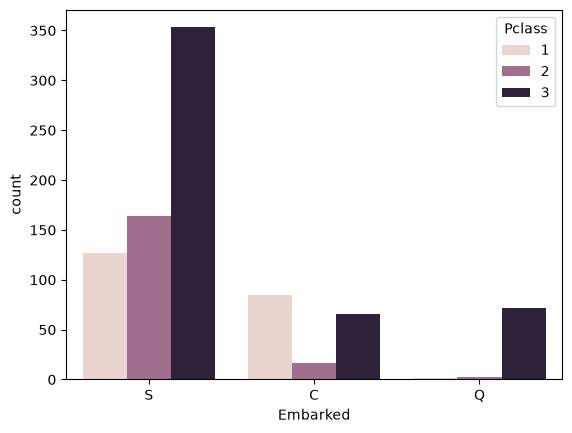

In [14]:
sns.countplot(data=df, x='Embarked', hue='Pclass');

Looking only at 3rd class to remove the class effect:

In [15]:
df_filtered = df[df['Pclass'] == 3].copy()

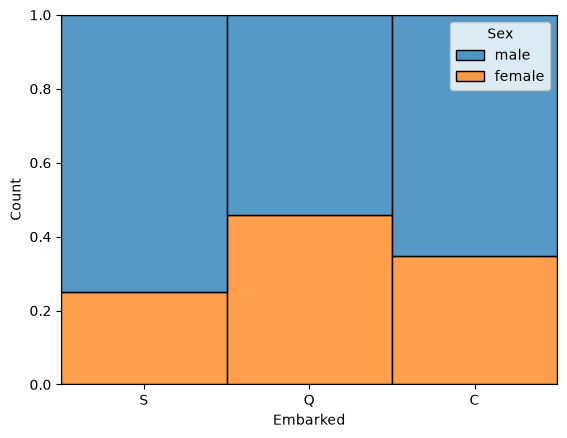

In [16]:
sns.histplot(data=df_filtered, x='Embarked', hue='Sex', multiple='fill');

In [17]:
df_filtered.groupby(['Embarked', 'Sex'])['Survived'].agg(['mean', 'sum', 'count'])

mean  sum  count
Embarked Sex                         
C        female  0.652174   15     23
         male    0.232558   10     43
Q        female  0.727273   24     33
         male    0.076923    3     39
S        female  0.375000   33     88
         male    0.128302   34    265

In [18]:
df_filtered.groupby(['Embarked', 'Parch'])['Survived'].agg(['mean', 'sum', 'count'])

mean  sum  count
Embarked Parch                      
C        0      0.255319   12     47
         1      0.642857    9     14
         2      0.750000    3      4
         3      1.000000    1      1
Q        0      0.421875   27     64
         1      0.000000    0      6
         2      0.000000    0      1
         5      0.000000    0      1
S        0      0.174074   47    270
         1      0.314286   11     35
         2      0.210526    8     38
         3      0.000000    0      2
         4      0.000000    0      3
         5      0.250000    1      4
         6      0.000000    0      1

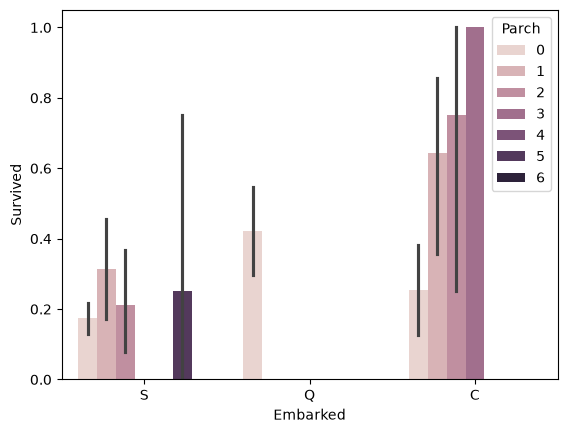

In [19]:
sns.barplot(data=df_filtered, x='Embarked', y='Survived', hue='Parch');

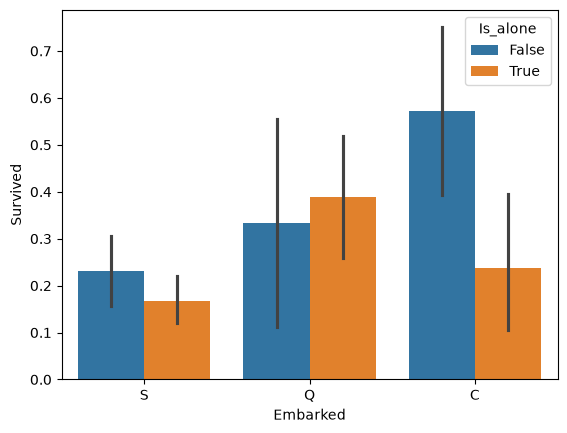

In [20]:
df_filtered['Is_alone'] = (df_filtered['Parch'] == 0) & (df_filtered['SibSp'] == 0)
sns.barplot(data=df_filtered, x='Embarked', y='Survived', hue='Is_alone');

### EDA conclusions

**Main survival factors**
- **Sex** is the strongest feature: women survived in ~74% of cases, men in ~19%.
- **Class:** the higher the class, the higher the survival rate.
- **Age:** children survived more often.

**Port of embarkation (`Embarked`)**
- Overall survival is higher for Cherbourg (C), mostly because more 1st-class passengers boarded there (a confounding factor).
- But the difference remains even inside 3rd class: C ~38% vs. S ~19%.
- Sex does not explain it: in S survival is lower for both men (13% vs. 23%) and women (37.5% vs. 65%).
- The difference is mostly in families: passengers travelling alone from C and S survived at similar rates (~24% and ~17%), while families from C did much better (~57%).
- Conclusion: I keep `Embarked`, it carries information beyond `Pclass` and `Sex`.

**Family**
- `Is_alone` has to use `SibSp + Parch`, otherwise couples without children are wrongly counted as alone.
- In 3rd class, having family slightly increases survival, most strongly for passengers from C.
- I add the features `FamilySize` and `Is_alone`.

**Method notes**
- Compare rates (`mean`, `barplot`, `multiple='fill'`), not counts (`countplot`).
- Always check group size (`count`): conclusions from groups of a few people are unreliable.

### Feature ideas

**Cabin.** `Cabin` is mostly missing, but whether it is known may itself be informative.

In [21]:
df['HasCabin'] = df['Cabin'].notna()
df.groupby('HasCabin')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
HasCabin,,,
False,0.299854,206,687
True,0.666667,136,204


In [22]:
df.groupby(['HasCabin', 'Pclass'])['Survived'].agg(['mean', 'sum', 'count'])

mean  sum  count
HasCabin Pclass                      
False    1       0.475000   19     40
         2       0.440476   74    168
         3       0.235908  113    479
True     1       0.664773  117    176
         2       0.812500   13     16
         3       0.500000    6     12

**Title from the name.** The title (Mr, Mrs, Miss, Master) encodes sex and approximate age, which helps to fill missing `Age` values.

In [23]:
df[['Age', 'Name']].sort_values('Age').head(15)

,Age,Name
803,0.42,"Thomas, Master. Assad Alexander"
755,0.67,"Hamalainen, Master. Viljo"
644,0.75,"Baclini, Miss. Eugenie"
469,0.75,"Baclini, Miss. Helene Barbara"
78,0.83,"Caldwell, Master. Alden Gates"
831,0.83,"Richards, Master. George Sibley"
305,0.92,"Allison, Master. Hudson Trevor"
827,1.00,"Mallet, Master. Andre"
381,1.00,"Nakid, Miss. Maria (""Mary"")"
164,1.00,"Panula, Master. Eino Viljami"


In [24]:
df['Title'] = df['Name'].str.extract(r', (Mr|Mrs|Miss|Master)\.', expand=False).fillna('Rare')
df['Title'].value_counts()

Title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64

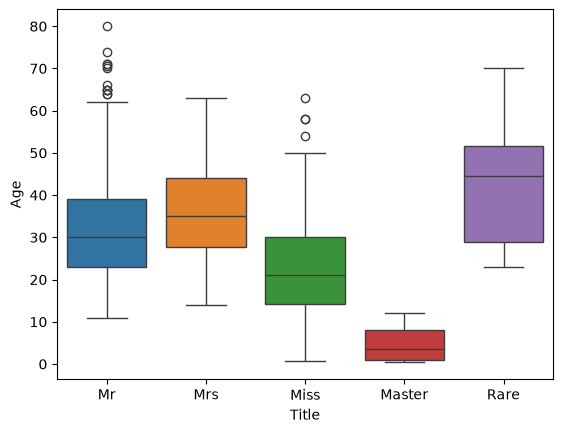

In [25]:
sns.boxplot(data=df, x='Title', y='Age', hue='Title');

"Miss" covers both girls and unmarried women. A Miss travelling with parents/children (`Parch > 0`) is much more likely to be a child:

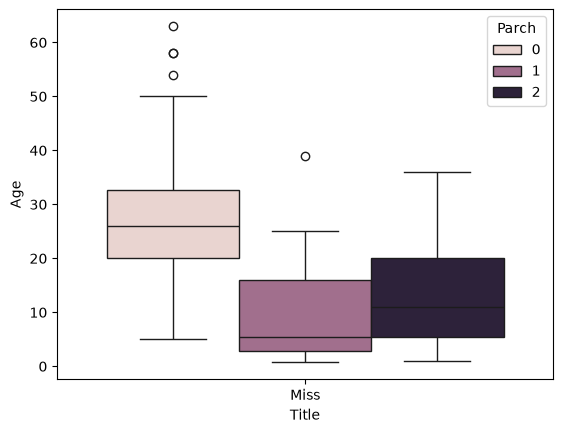

In [26]:
sns.boxplot(data=df[df['Title'] == 'Miss'], x='Title', y='Age', hue='Parch');

In [27]:
df['AgeGroup'] = df['Title']
df.loc[(df['Title'] == 'Miss') & (df['Parch'] > 0), 'AgeGroup'] = 'Miss_child'
df.loc[(df['Title'] == 'Miss') & (df['Parch'] == 0), 'AgeGroup'] = 'Miss_adult'

df.groupby('AgeGroup')['Age'].median()

AgeGroup
Master         3.5
Miss_adult    26.0
Miss_child     9.0
Mr            30.0
Mrs           35.0
Rare          44.5
Name: Age, dtype: float64

Missing `Age` will be filled with the median of the passenger's `AgeGroup`.

## Preprocessing

### Baseline: manual preprocessing

Features that don't depend on statistics are added the same way to train and test. Statistics for filling missing values are computed on train only, to avoid leakage.

In [28]:
def add_features_baseline(df):
    df = df.copy()

    df['HasCabin'] = df['Cabin'].notna()
    df['Is_alone'] = (df['Parch'] == 0) & (df['SibSp'] == 0)
    df['FamilySize'] = df['Parch'] + df['SibSp']

    title = df['Name'].str.extract(r', (Mr|Mrs|Miss|Master)\.', expand=False).fillna('Rare')

    df['AgeGroup'] = title
    df.loc[(title == 'Miss') & (df['Parch'] > 0), 'AgeGroup'] = 'Miss_child'
    df.loc[(title == 'Miss') & (df['Parch'] == 0), 'AgeGroup'] = 'Miss_adult'

    df = df.drop('Cabin', axis=1)
    return df


def fill_missing(df, stats):
    df = df.copy()

    df['Age'] = df['Age'].fillna(df['AgeGroup'].map(stats['age_medians']))
    df['Fare'] = df['Fare'].fillna(stats['fare_median'])
    df['Embarked'] = df['Embarked'].fillna(stats['embarked_mode'])

    return df


def modify_features_baseline(df):
    df = df.copy()

    sex = {'male': 0, 'female': 1}
    df['Sex'] = df['Sex'].map(sex)

    df = pd.get_dummies(df, columns=['Embarked', 'AgeGroup'], drop_first=True)

    df = df.drop(['Name', 'Ticket', 'Fare', 'PassengerId'], axis=1)

    return df

In [29]:
train_raw = pd.read_csv('data/train.csv')
test_raw = pd.read_csv('data/test.csv')

train = add_features_baseline(train_raw)
test = add_features_baseline(test_raw)

stats = {
    'age_medians': train.groupby('AgeGroup')['Age'].median(),
    'fare_median': train['Fare'].median(),
    'embarked_mode': train['Embarked'].mode()[0],
}

train = fill_missing(train, stats)
test = fill_missing(test, stats)

print(train.isna().sum().sum(), test.isna().sum().sum())

0 0


In [30]:
train = modify_features_baseline(train)
test = modify_features_baseline(test)

# test may lack some dummy columns, so align it with train
test = test.reindex(columns=train.columns, fill_value=0)
train.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,HasCabin,Is_alone,FamilySize,Embarked_Q,Embarked_S,AgeGroup_Miss_adult,AgeGroup_Miss_child,AgeGroup_Mr,AgeGroup_Mrs,AgeGroup_Rare
0,0,3,0,22.0,1,0,False,False,1,False,True,False,False,True,False,False
1,1,1,1,38.0,1,0,True,False,1,False,False,False,False,False,True,False
2,1,3,1,26.0,0,0,False,True,0,False,True,True,False,False,False,False
3,1,1,1,35.0,1,0,True,False,1,False,True,False,False,False,True,False
4,0,3,0,35.0,0,0,False,True,0,False,True,False,False,True,False,False


## Modeling

### Baseline: Logistic Regression

In [31]:
X_train = train.drop('Survived', axis=1)
y_train = train['Survived']
X_test = test.drop('Survived', axis=1)

scaler = StandardScaler()
scaled_X_train = scaler.fit_transform(X_train)
scaled_X_test = scaler.transform(X_test)

In [32]:
baseline_model = LogisticRegression()
scores = cross_val_score(baseline_model, scaled_X_train, y_train, cv=5, scoring='accuracy')
scores.mean(), scores.std()

(np.float64(0.8294080723118448), np.float64(0.02474668698594069))

In [33]:
baseline_model.fit(scaled_X_train, y_train)
predictions = baseline_model.predict(scaled_X_test)

submission = pd.DataFrame({
    'PassengerId': test_raw['PassengerId'],
    'Survived': predictions
})
submission.to_csv('baseline.csv', index=False)

### Pipeline

The same steps (imputation, encoding, scaling) moved into a `Pipeline` with a `ColumnTransformer`, so they are fitted inside each CV fold. One new feature: `Ticket_count`, the number of passengers travelling on the same ticket.

In [34]:
def add_features(df, ticket_counts):
    df = df.copy()

    df['HasCabin'] = df['Cabin'].notna()
    df['Is_alone'] = (df['Parch'] == 0) & (df['SibSp'] == 0)
    df['FamilySize'] = df['Parch'] + df['SibSp']

    title = df['Name'].str.extract(r', (Mr|Mrs|Miss|Master)\.', expand=False).fillna('Rare')

    df['AgeGroup'] = title
    df.loc[(title == 'Miss') & (df['Parch'] > 0), 'AgeGroup'] = 'Miss_child'
    df.loc[(title == 'Miss') & (df['Parch'] == 0), 'AgeGroup'] = 'Miss_adult'

    df['Ticket_count'] = df['Ticket'].map(ticket_counts)

    df = df.drop('Cabin', axis=1)
    return df


def modify_features(df):
    df = df.copy()

    sex = {'male': 0, 'female': 1}
    df['Sex'] = df['Sex'].map(sex)

    df = df.drop(['Name', 'Ticket', 'PassengerId'], axis=1)

    return df

In [35]:
# Counted on train + test together, otherwise a family split between the sets gets different values.
# Survived is not used here, so there is no leakage.
ticket_counts = pd.concat([train_raw, test_raw])['Ticket'].value_counts()

train = modify_features(add_features(train_raw, ticket_counts))
test = modify_features(add_features(test_raw, ticket_counts))

X_train = train.drop('Survived', axis=1)
y_train = train['Survived']
X_test = test

In [36]:
numeric = ['Age', 'Fare', 'FamilySize', 'SibSp', 'Parch', 'Ticket_count']
categorial = ['Embarked', 'AgeGroup', 'Pclass']
binary = ['Sex', 'HasCabin', 'Is_alone']

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, numeric),
    ('cat', cat_pipe, categorial),
    ('bin', 'passthrough', binary)
])

### Logistic Regression

In [37]:
full_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression())
])

scores = cross_val_score(full_pipe, X_train, y_train, cv=5)
scores.mean(), scores.std()

(np.float64(0.8282656455966355), np.float64(0.025871135151289897))

In [38]:
param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100],  # smaller C = stronger regularization
}

grid = GridSearchCV(full_pipe, param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'model__C': 1}
0.8282656455966355


In [39]:
best_lr = grid.best_estimator_

names = best_lr.named_steps['prep'].get_feature_names_out()
coefs = best_lr.named_steps['model'].coef_[0]

coef_table = pd.Series(coefs, index=names)
coef_table.sort_values(key=abs, ascending=False)

cat__AgeGroup_Master        1.671170
bin__Sex                    1.531790
cat__AgeGroup_Mr           -1.418594
cat__AgeGroup_Rare         -0.800599
cat__Pclass_3              -0.799995
bin__HasCabin               0.796488
cat__Pclass_1               0.588762
cat__AgeGroup_Mrs           0.559328
num__SibSp                 -0.458334
num__FamilySize            -0.413173
bin__Is_alone              -0.357804
num__Age                   -0.320229
cat__Embarked_S            -0.272963
num__Parch                 -0.200002
cat__AgeGroup_Miss_adult   -0.174850
cat__Pclass_2               0.166198
num__Ticket_count           0.150862
cat__Embarked_C             0.122757
cat__AgeGroup_Miss_child    0.118511
num__Fare                   0.111408
cat__Embarked_Q             0.105171
dtype: float64

### KNN

In [40]:
knn_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', KNeighborsClassifier())
])

scores = cross_val_score(knn_pipe, X_train, y_train, cv=5)
scores.mean(), scores.std()

(np.float64(0.8002573598644153), np.float64(0.02393657035534274))

In [41]:
param_grid = {
    'model__n_neighbors': range(1, 31),  # small k is sensitive to noise and overfits easily
    'model__weights': ['uniform', 'distance'],  # equal votes or closer neighbors weigh more
    'model__p': [1, 2]  # Manhattan is less sensitive to outliers than Euclidean
}

grid_knn = GridSearchCV(knn_pipe, param_grid, cv=5, scoring='accuracy')
grid_knn.fit(X_train, y_train)

print(grid_knn.best_params_)
print(grid_knn.best_score_)

{'model__n_neighbors': 28, 'model__p': 1, 'model__weights': 'uniform'}
0.8238214801330738


### SVM

In [42]:
svm_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', SVC())
])

scores = cross_val_score(svm_pipe, X_train, y_train, cv=5)
scores.mean(), scores.std()

(np.float64(0.8349946644906158), np.float64(0.02386213557397837))

In [43]:
param_grid = [
    {
        'model__kernel': ['linear'],
        'model__C': [0.1, 1, 10]
    },
    {
        'model__kernel': ['rbf'],
        'model__C': [0.3, 0.5, 1, 2, 3, 5],
        'model__gamma': ['scale', 0.01, 0.1, 1, 10]
    }
]

grid_svm = GridSearchCV(svm_pipe, param_grid, cv=5, scoring='accuracy')
grid_svm.fit(X_train, y_train)

print(grid_svm.best_params_)
print(grid_svm.best_score_)

{'model__C': 2, 'model__gamma': 0.1, 'model__kernel': 'rbf'}
0.8383654510074697


### Decision Tree

Same preprocessing without `StandardScaler`: trees don't need scaling, and raw values make the splits readable.

In [44]:
numeric_tree = ['Age', 'Fare', 'FamilySize', 'SibSp', 'Parch', 'Ticket_count']
categorial_tree = ['Embarked', 'AgeGroup', 'Pclass']
binary_tree = ['Sex', 'HasCabin', 'Is_alone']

num_pipe_tree = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_pipe_tree = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_tree = ColumnTransformer([
    ('num', num_pipe_tree, numeric_tree),
    ('cat', cat_pipe_tree, categorial_tree),
    ('bin', 'passthrough', binary_tree)
])

tree_pipe = Pipeline([
    ('prep', preprocessor_tree),
    ('model', DecisionTreeClassifier(random_state=101))
])

scores = cross_val_score(tree_pipe, X_train, y_train, cv=5)
scores.mean(), scores.std()

(np.float64(0.7856443412215178), np.float64(0.029518233217757504))

In [45]:
param_grid = {
    'model__max_depth': [3, 4, 5, 6, 8, 10, None],
    'model__min_samples_leaf': [1, 2, 5, 10, 20]
}

tree_grid = GridSearchCV(tree_pipe, param_grid, cv=5, scoring='accuracy')
tree_grid.fit(X_train, y_train)

print(tree_grid.best_params_)
print(tree_grid.best_score_)

{'model__max_depth': 4, 'model__min_samples_leaf': 5}
0.8271357730211537


In [46]:
best_tree = tree_grid.best_estimator_
names = best_tree.named_steps['prep'].get_feature_names_out()
importances = best_tree.named_steps['model'].feature_importances_

pd.Series(importances, index=names).sort_values(ascending=False)

cat__AgeGroup_Mr            0.606639
num__FamilySize             0.146154
num__Fare                   0.123045
cat__Pclass_3               0.041946
cat__AgeGroup_Rare          0.041865
num__Age                    0.028350
bin__HasCabin               0.012002
bin__Sex                    0.000000
cat__Pclass_2               0.000000
cat__Pclass_1               0.000000
cat__AgeGroup_Mrs           0.000000
cat__AgeGroup_Miss_adult    0.000000
cat__AgeGroup_Miss_child    0.000000
cat__AgeGroup_Master        0.000000
cat__Embarked_S             0.000000
cat__Embarked_Q             0.000000
cat__Embarked_C             0.000000
num__Ticket_count           0.000000
num__Parch                  0.000000
num__SibSp                  0.000000
bin__Is_alone               0.000000
dtype: float64

### Final submission: SVM

The tuned SVM has the best CV accuracy, so it is used for the final Kaggle submission.

In [47]:
predictions = grid_svm.best_estimator_.predict(X_test)

submission = pd.DataFrame({
    'PassengerId': test_raw['PassengerId'],
    'Survived': predictions
})
submission.to_csv('solution.csv', index=False)

## Results

5-fold CV accuracy on the training set and the public Kaggle score of each submission:

| Model | CV accuracy (default) | CV accuracy (tuned) | Best parameters | Kaggle score |
|---|---|---|---|---|
| Baseline: all women survive | - | - | - | 0.76555 |
| Logistic Regression, manual preprocessing | 0.829 | - | - | 0.77272 |
| Logistic Regression, pipeline | 0.828 | 0.828 | C=1 | - |
| KNN | 0.800 | 0.824 | k=28, p=1, uniform | - |
| **SVM** | 0.835 | **0.838** | rbf, C=2, gamma=0.1 | **0.77751** |
| Decision Tree | 0.786 | 0.827 | max_depth=4, min_samples_leaf=5 | - |

The CV standard deviation is about 0.025, so the ~1 point differences between the tuned models are within noise.

## Error analysis

Out-of-fold predictions of the tuned SVM on the training set, to see which passengers the model gets wrong.

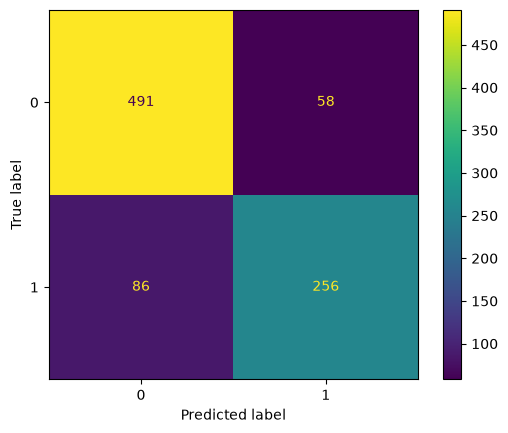

In [48]:
predict = cross_val_predict(grid_svm.best_estimator_, X_train, y_train, cv=5)
ConfusionMatrixDisplay.from_predictions(y_train, predict)
plt.savefig('images/svm_confusion_matrix.png', bbox_inches='tight');

In [49]:
check = add_features(train_raw, ticket_counts)
check['Pred'] = predict
check['Error'] = check['Survived'] != predict

check.groupby(['AgeGroup', 'Pclass'])['Error'].agg(['mean', 'sum', 'count'])

mean  sum  count
AgeGroup   Pclass                      
Master     1       0.000000    0      3
           2       0.000000    0      9
           3       0.035714    1     28
Miss_adult 1       0.033333    1     30
           2       0.095238    2     21
           3       0.388060   26     67
Miss_child 1       0.062500    1     16
           2       0.000000    0     13
           3       0.200000    7     35
Mr         1       0.345794   37    107
           2       0.087912    8     91
           3       0.109718   35    319
Mrs        1       0.023810    1     42
           2       0.097561    4     41
           3       0.357143   15     42
Rare       1       0.333333    6     18
           2       0.000000    0      9

### Women in 3rd class

In [50]:
check_women = check[(check['AgeGroup'].isin(['Miss_adult', 'Mrs'])) & (check['Pclass'] == 3)]
check_women.groupby(['Embarked', 'FamilySize'])[['Error', 'Pred', 'Survived']].agg(['mean', 'sum', 'count'])

Error                Pred            Survived      \
                         mean sum count      mean sum count      mean sum   
Embarked FamilySize                                                         
C        0           0.200000   1     5  1.000000   5     5  0.800000   4   
         1           0.666667   4     6  1.000000   6     6  0.333333   2   
         2           0.333333   1     3  1.000000   3     3  0.666667   2   
         3           0.000000   0     1  1.000000   1     1  1.000000   1   
Q        0           0.240000   6    25  1.000000  25    25  0.760000  19   
         1           0.000000   0     4  1.000000   4     4  1.000000   4   
         2           0.500000   1     2  1.000000   2     2  0.500000   1   
         5           0.000000   0     1  0.000000   0     1  0.000000   0   
S        0           0.500000  15    30  0.966667  29    30  0.466667  14   
         1           0.466667   7    15  0.933333  14    15  0.466667   7   
         2           0.555556   5     9  0.777778   7     9  0.444444   4   
         3           0.000000   0     1  1.000000   1     1  1.000000   1   
         4           0.000000   0     2  0.000000   0     2  0.000000   0   
         5           0.000000   0     2  0.000000   0     2  0.000000   0   
         6           0.500000   1     2  0.000000   0     2  0.500000   1   
         7           0.000000   0     1  0.000000   0     1  0.000000   0   

                           
                    count  
Embarked FamilySize        
C        0              5  
         1              6  
         2              3  
         3              1  
Q        0             25  
         1              4  
         2              2  
         5              1  
S        0             30  
         1             15  
         2              9  
         3              1  
         4              2  
         5              2  
         6              2  
         7              1

The model predicts survival for almost all 3rd-class women. For women from Southampton (S) with a family of at most two, it predicts survival for 50 of 54, while only 25 actually survived, so half of its predictions in this group are wrong.

In the plots below, survivors and non-survivors in this group have almost the same fare and age, and the `Parch` and `Ticket_count` groups are too small to draw conclusions.

In [51]:
check_women_2 = check_women[(check_women['Embarked'] == 'S') & (check_women['FamilySize'] <= 2)]
check_women_2.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,HasCabin,Is_alone,FamilySize,AgeGroup,Ticket_count,Pred,Error
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,False,True,0,Miss_adult,1,1,False
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,S,False,False,2,Mrs,3,1,False
14,15,0,3,"Vestrom, Miss. Hulda Amanda Adolfina",female,14.0,0,0,350406,7.8542,S,False,True,0,Miss_adult,1,1,True
18,19,0,3,"Vander Planke, Mrs. Julius (Emelia Maria Vande...",female,31.0,1,0,345763,18.0000,S,False,False,1,Mrs,2,1,True
38,39,0,3,"Vander Planke, Miss. Augusta Maria",female,18.0,2,0,345764,18.0000,S,False,False,2,Miss_adult,2,1,True


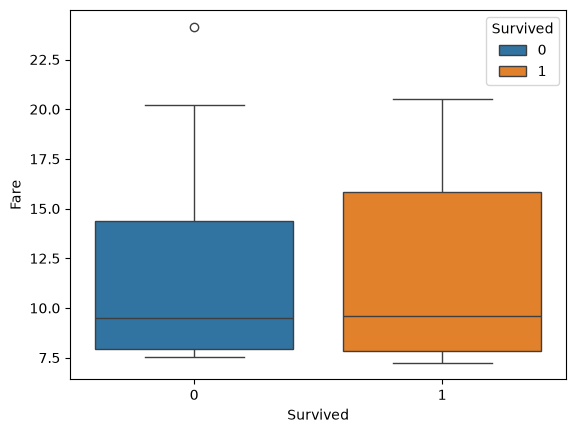

In [52]:
sns.boxplot(data=check_women_2, y='Fare', x='Survived', hue='Survived');

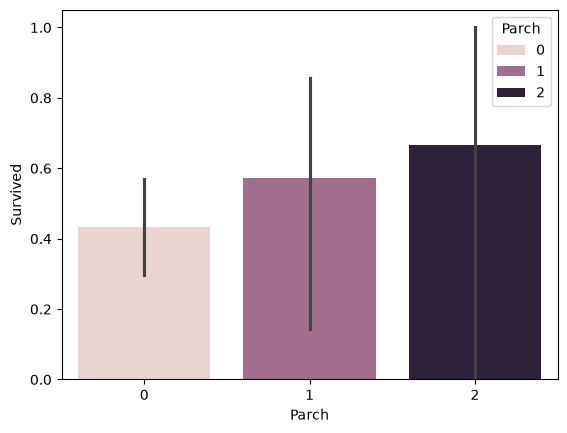

In [53]:
sns.barplot(data=check_women_2, x='Parch', y='Survived', hue='Parch');

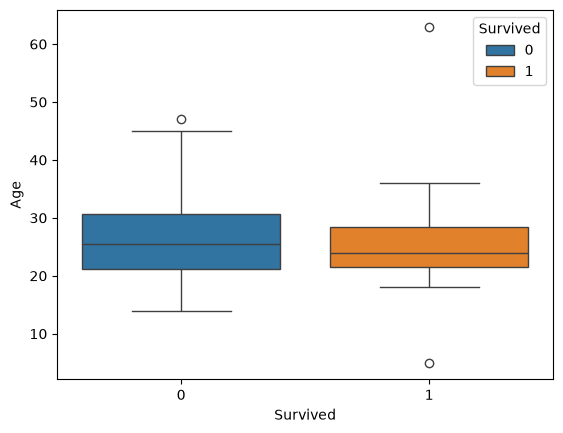

In [54]:
sns.boxplot(data=check_women_2, x='Survived', y='Age', hue='Survived');

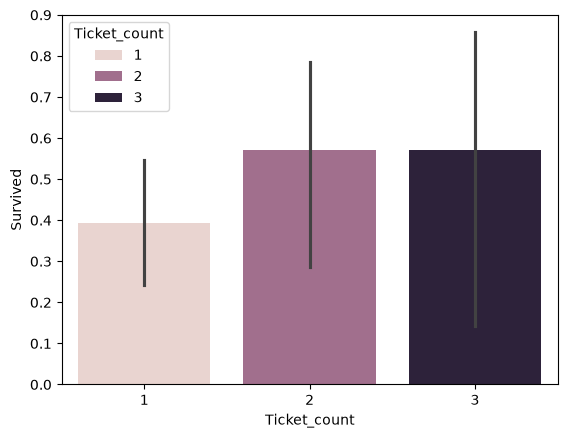

In [55]:
sns.barplot(data=check_women_2, x='Ticket_count', y='Survived', hue='Ticket_count');

## Conclusions

The tuned SVM (RBF kernel, C=2, gamma=0.1) has the best CV accuracy (0.838) and scored 0.77751 on Kaggle, above the logistic regression baseline (0.77272) and the "all women survive" baseline (0.76555). CV accuracy is about 6 points higher than the Kaggle score, so the CV estimate is optimistic.

Most of the signal comes from the engineered features: `AgeGroup` (from the title) and `Sex` have the largest logistic regression coefficients, and `AgeGroup_Mr` is the main split of the decision tree. Error analysis shows where the model is weakest: 3rd-class women, especially from Southampton, and 1st-class men (35% error). A next step would be finding features that separate survivors among 3rd-class women.